# Virtual-site benchmark datasets
Public datasets where every compound has **both** a crystal structure and a measured potency/affinity; helpers live in `datasets.py`.

Set up the environment with `mamba env create -f environment.yml` (env `vsites-datasets`). `data/` is not tracked by git: the first run downloads the raw data (~0.5 GB, cached in `data/raw/`) and builds a table of structure–potency pairs per dataset in `data/<dataset>/pairs.csv`.

In [1]:
%load_ext autoreload
%autoreload 2
import datasets as ds

## Sources
Each entry names a structure source and a potency source (see the docstring of `datasets.py` for all options); only compounds found in both are kept. The key is just a display name.

In [2]:
SOURCES = {
    "COVID Moonshot (SARS-CoV-2 Mpro)": {
        "structures": {
            "from": "zip",
            "url": "https://fs.polarishub.io/2025-01-asap-discovery/raw_data_package.zip",
            "ligand_glob": "ligand-posing/SARS-CoV-2_Mpro-*/ligand.sdf",
            "id_pattern": r"(Mpro-\w+?)_CONFIDENTIAL/",
        },
        "potency": {
            "from": "csv",
            "url": "https://github.com/asapdiscovery/COVID_moonshot_data_clean/tree/main",
            "file": "cdd_noncovalent_dates_2023_10_18_filt.csv",
            "columns": {"Canonical_PostEra_ID": "compound_id", "suspected_SMILES": "smiles", "IC50_(µM)": "value"},
            "unit": "uM",
        },
        "meta": {"target": "SARS-CoV-2 Mpro", "assay": "Biochemical potency (FRET)"},
    },
    "ASAP Mac1 (SARS-CoV-2 nsp3)": {
        "structures": {"from": "pdb_group", "group": "G_1002283", "compound_id_pattern": r"(ASAP-\d+)"},
        "potency": {"from": "chembl", "document": "CHEMBL5441456"},
        "meta": {"target": "SARS-CoV-2 nsp3 Mac1", "assay": "Biochemical potency (FRET)"},
    },
    "Polaris 2025 test (SARS-CoV-2 Mpro)": {
        "structures": {
            "from": "polaris",
            "dataset": "asap-discovery/antiviral-ligand-poses-2025-unblinded",
            "filter": {"Set": "Test", "Protein Label": "SARS-CoV-2 Mpro"},
        },
        "potency": {
            "from": "polaris",
            "dataset": "asap-discovery/antiviral-potency-2025-unblinded",
            "column": "pIC50 (SARS-CoV-2 Mpro)",
        },
        "meta": {"target": "SARS-CoV-2 Mpro", "assay": "Biochemical potency (FRET)"},
    },
    "Polaris 2025 test (MERS-CoV Mpro)": {
        "structures": {
            "from": "polaris",
            "dataset": "asap-discovery/antiviral-ligand-poses-2025-unblinded",
            "filter": {"Set": "Test", "Protein Label": "MERS-CoV Mpro"},
        },
        "potency": {
            "from": "polaris",
            "dataset": "asap-discovery/antiviral-potency-2025-unblinded",
            "column": "pIC50 (MERS-CoV Mpro)",
        },
        "meta": {"target": "MERS-CoV Mpro", "assay": "Biochemical potency (FRET)"},
    },
    "OpenBind (EV-A71 2A protease)": {
        "structures": {
            "from": "zip",
            "url": "https://zenodo.org/records/22142262/files/OpenBind_EV-A71_2A.zip?download=1",
            "ligand_glob": "*/structures/*/*/*_ligand_ref.sdf",
            "protein_file": "{structure_id}_complex_ref.pdb",
            "clean": True,
            "annotations": {
                "file": "*/EV-A71_2A_metadata.csv",
                "id_column": "complex_name",
                "columns": ["fragment_screen", "covalent", "pb_valid_ref", "suspected_artefact"],
            },
            "query": "pb_valid_ref and not suspected_artefact",
        },
        "potency": {
            "from": "csv",
            "url": "https://zenodo.org/records/22142262/files/OpenBind_EV-A71_2A.zip?download=1",
            "file": "*/EV-A71_2A_metadata.csv",
            "columns": {"compound_group": "compound_id", "experimental_pKD": "value"},
            "unit": "pX",
            "potency_type": "KD",
        },
        "meta": {"target": "EV-A71 2A protease (CVA16 construct)", "assay": "Affinity (Creoptix)"},
    },
}

## Build / load structure–potency pairs

In [3]:
df = ds.load_all(SOURCES)
df.head()

,dataset,structure_id,compound_id,smiles,potency_type,pX,n_measurements,expt_dg,potency_stereo,target,assay,fragment_screen,covalent,pb_valid_ref,suspected_artefact
0,COVID Moonshot (SARS-CoV-2 Mpro),Mpro-P0008_0A,ERI-UCB-ce40166b-17,O=C1CC(Oc2cc(Cl)cc(OCCNC(=O)c3cc(=O)[nH]c4cccc...,IC50,5.958607,1,-8.128995,unspecified,SARS-CoV-2 Mpro,Biochemical potency (FRET),NaN,NaN,NaN,NaN
1,COVID Moonshot (SARS-CoV-2 Mpro),Mpro-P0008_0B,ERI-UCB-ce40166b-17,O=C1CC(Oc2cc(Cl)cc(OCCNC(=O)c3cc(=O)[nH]c4cccc...,IC50,5.958607,1,-8.128995,unspecified,SARS-CoV-2 Mpro,Biochemical potency (FRET),NaN,NaN,NaN,NaN
2,COVID Moonshot (SARS-CoV-2 Mpro),Mpro-P0009_0A,MAT-POS-f2460aef-2,CC(C)(C)c1ccc(N(C(=O)c2ccco2)[C@@H](C(=O)NCCc2...,IC50,6.390852,4,-8.718682,relative,SARS-CoV-2 Mpro,Biochemical potency (FRET),NaN,NaN,NaN,NaN
3,COVID Moonshot (SARS-CoV-2 Mpro),Mpro-P0009_0B,MAT-POS-f2460aef-2,CC(C)(C)c1ccc(N(C(=O)c2ccco2)[C@@H](C(=O)NCCc2...,IC50,6.390852,4,-8.718682,relative,SARS-CoV-2 Mpro,Biochemical potency (FRET),NaN,NaN,NaN,NaN
4,COVID Moonshot (SARS-CoV-2 Mpro),Mpro-P0010_0A,EDG-MED-5d232de5-8,[H][C@@]1(c2cccc(Cl)c2)CCN(c2cncc3ccccc23)C1=O,IC50,4.403403,1,-6.007316,defined,SARS-CoV-2 Mpro,Biochemical potency (FRET),NaN,NaN,NaN,NaN


## What do we have?

In [4]:
ds.summarise(df)

,potency_type,n_structures,n_compounds,pX_min,pX_max,expt_dg_min,expt_dg_max
dataset,,,,,,,
COVID Moonshot (SARS-CoV-2 Mpro),IC50,427,263,4.01,7.71,-10.51,-5.48
ASAP Mac1 (SARS-CoV-2 nsp3),IC50,72,68,3.91,7.82,-10.67,-5.34
Polaris 2025 test (SARS-CoV-2 Mpro),IC50,79,68,4.51,8.46,-11.54,-6.15
Polaris 2025 test (MERS-CoV Mpro),IC50,86,83,3.75,7.60,-10.37,-5.12
OpenBind (EV-A71 2A protease),KD,631,482,3.44,7.94,-10.83,-4.69


In [5]:
ds.motif_counts(df)

n  \
dataset                             COVID Moonshot (SARS-CoV-2 Mpro)   
aromatic Cl/Br/I (sigma hole)                                    226   
aliphatic Cl/Br/I                                                  0   
aromatic N acceptor (pyridine-like)                              254   
carbonyl O                                                       262   
ether / hydroxyl O                                                95   
nitrile N                                                         16   
divalent S                                                         1   

                                                                 \
dataset                             ASAP Mac1 (SARS-CoV-2 nsp3)   
aromatic Cl/Br/I (sigma hole)                                 5   
aliphatic Cl/Br/I                                             0   
aromatic N acceptor (pyridine-like)                          66   
carbonyl O                                                   39   
ether / hydroxyl O                                           20   
nitrile N                                                     5   
divalent S                                                    0   

                                                                         \
dataset                             Polaris 2025 test (SARS-CoV-2 Mpro)   
aromatic Cl/Br/I (sigma hole)                                        27   
aliphatic Cl/Br/I                                                     0   
aromatic N acceptor (pyridine-like)                                  67   
carbonyl O                                                           67   
ether / hydroxyl O                                                   11   
nitrile N                                                             1   
divalent S                                                            0   

                                                                       \
dataset                             Polaris 2025 test (MERS-CoV Mpro)   
aromatic Cl/Br/I (sigma hole)                                      50   
aliphatic Cl/Br/I                                                   1   
aromatic N acceptor (pyridine-like)                                83   
carbonyl O                                                         83   
ether / hydroxyl O                                                 21   
nitrile N                                                           5   
divalent S                                                          1   

                                                                   \
dataset                             OpenBind (EV-A71 2A protease)   
aromatic Cl/Br/I (sigma hole)                                  71   
aliphatic Cl/Br/I                                               1   
aromatic N acceptor (pyridine-like)                           230   
carbonyl O                                                    477   
ether / hydroxyl O                                            122   
nitrile N                                                      15   
divalent S                                                    253   

                                                                frac  \
dataset                             COVID Moonshot (SARS-CoV-2 Mpro)   
aromatic Cl/Br/I (sigma hole)                                   0.86   
aliphatic Cl/Br/I                                               0.00   
aromatic N acceptor (pyridine-like)                             0.97   
carbonyl O                                                      1.00   
ether / hydroxyl O                                              0.36   
nitrile N                                                       0.06   
divalent S                                                      0.00   

                                                                 \
dataset                             ASAP Mac1 (SARS-CoV-2 nsp3)   
aromatic Cl/Br/I (sigma hole)                              0.07   
aliphati

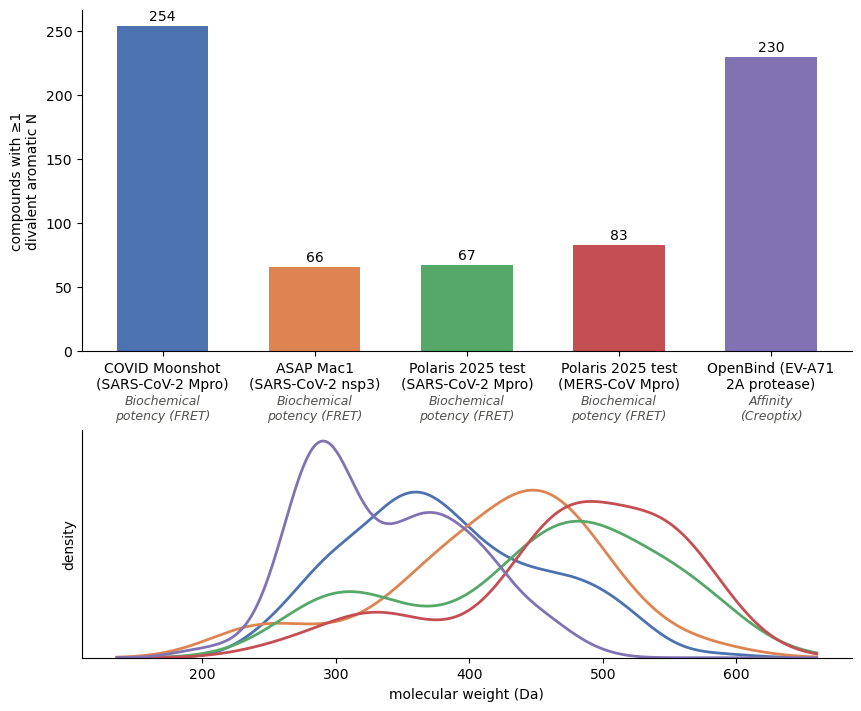

In [6]:
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from rdkit import Chem
from rdkit.Chem.Descriptors import MolWt
from scipy.stats import gaussian_kde

colors = dict(zip(SOURCES, sns.color_palette("deep", len(SOURCES))))  # one colour per dataset, both panels
compounds = df.drop_duplicates(["dataset", "compound_id"])
mw = compounds.smiles.map(lambda s: MolWt(Chem.MolFromSmiles(s)))
n_arom_n = ds.motif_counts(df, {"aromatic N": "[nX2]"})["n"].loc["aromatic N"]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(1.5 + 1.4 * len(n_arom_n), 7), height_ratios=[3, 2],
                                  layout="constrained")
# top: compounds with >=1 divalent (pyridine-like) aromatic N, one bar per dataset
bars = top.bar([textwrap.fill(n, 18, break_on_hyphens=False) for n in n_arom_n.index], n_arom_n.values,
               color=[colors[n] for n in n_arom_n.index], width=0.6)
assays = df.groupby("dataset", sort=False)["assay"].first()
for label, name in zip(top.get_xticklabels(), n_arom_n.index):  # assay type under each dataset name
    top.annotate(textwrap.fill(assays[name], 18), xy=(0.5, 0), xycoords=label, xytext=(0, -2),
                 textcoords="offset points", ha="center", va="top", fontsize=9, style="italic", color="#52514e")
top.bar_label(bars, padding=2)
top.set_ylabel("compounds with ≥1\ndivalent aromatic N")
# bottom: molecular weight distribution of each dataset's compounds
grid = np.linspace(mw.min() - 50, mw.max() + 50, 500)
for name, values in mw.groupby(compounds.dataset, sort=False):
    bottom.plot(grid, gaussian_kde(values)(grid), color=colors[name], lw=2)
bottom.set(xlabel="molecular weight (Da)", ylabel="density", yticks=[], ylim=(0, None))
for ax in (top, bottom):
    ax.spines[["top", "right"]].set_visible(False)

## Optional: write structure files
Writes the crystal ligand and the protein of every pair to `data/<dataset>/structures/<structure_id>/{ligand.sdf,protein.pdb}` (~0.5 GB). Moonshot and Polaris structures come prepared with hydrogens; Mac1 and OpenBind proteins are the deposited models without ligands, waters and additives (highest-occupancy conformer).

In [7]:
WRITE_STRUCTURES = False  # set to True to write ligand.sdf + protein.pdb for every pair
if WRITE_STRUCTURES:
    ds.write_structures(SOURCES)